# Actividad 3: Transformación, enriquecimiento y respuestas de negocio
## Análisis de precios de oferta por m² – Casas vs Apartamentos en Colombia 2026

**Dataset:** [`aptologia/casa-vs-apartamento-precio-m2-ciudades-colombia-2026`](https://huggingface.co/datasets/aptologia/casa-vs-apartamento-precio-m2-ciudades-colombia-2026)  
**Fuente:** Aptología | Licencia: CC BY 4.0  
**Alcance:** 38 ciudades de Colombia

### Flujo del notebook
HFDatasetLoader → DataFrame original → Controles de calidad → Enriquecimiento → Análisis de preguntas de negocio → Exportación de datos y reporte .txt

- `src/clases_po/hf_loader.py` → clase `HFDatasetLoader`  
- `src/clases_po/reportes.py` → clase `Reportes`  
- Este notebook coordina todo el proceso y genera los entregables finales.
   

## Preguntas de negocio (AE2)

1. ¿En qué ciudades de Colombia la tendencia del mercado se invierte y comprar casa resulta más costoso que comprar apartamento?  
   *Utilidad:* Identificar municipios atípicos (vivienda campestre o de alto valor percibido).

2. ¿Cuáles son las ciudades con la mayor brecha de descuento en casas frente a apartamentos, y qué tanto influye la dinámica turística o costera?  
   *Utilidad:* Entender el efecto del turismo y la densificación vertical en ciudades de playa.

3. ¿Cómo se comporta el mercado inmobiliario dentro de las principales áreas metropolitanas (Valle de Aburrá vs. Sabana de Bogotá)?  
   *Utilidad:* Comparar municipios aledaños a las grandes capitales.

4. ¿Existe una correlación directa entre el volumen de oferta analizado (n_si y n_no) y el nivel de precios del metro cuadrado?  
   *Utilidad:* Evaluar si los mercados con mayor liquidez concentran los precios más altos.

5. ¿Cuál es la proporción general de costos a escala nacional entre ambas tipologías de vivienda?  
   *Utilidad:* Determinar el ahorro o prima promedio al preferir casa vs apartamento.


## Preparar el entorno e importar las clases ##

In [4]:
import sys # Módulo del sistema; permite modificar las rutas donde Python busca módulos
from pathlib import Path  # Para manejar rutas de carpetas
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


ROOT = Path.cwd().resolve()  # Empezamos en la carpeta desde donde se ejecuta el notebook
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():  # Mientras no encontremos src/clases_po...
    ROOT = ROOT.parent  # ...subimos una carpeta

sys.path.insert(0, str(ROOT / "src"))  # Agregamos src/ a las rutas de búsqueda de Python

import pandas as pd  # Librería para trabajar con DataFrames
from clases_po import HFDatasetLoader, Reportes  # Importamos las dos clases desde src/clases_po

pd.set_option("display.float_format", "{:,.2f}".format)  # Muestra los decimales con 2 cifras y separador de miles.
sns.set_theme(style="whitegrid", palette="muted")
loader = HFDatasetLoader(  # Creamos el cargador
    dataset_name="aptologia/casa-vs-apartamento-precio-m2-ciudades-colombia-2026",  # Identificador del dataset en Hugging Face
    split="train",  # División a descargar (es la única que tiene)
    filename="datos/vivienda_colombia.csv",  # Copia de los datos originales en CSV
)

df = loader.load()  # Descargamos el dataset y lo obtenemos como DataFrame de pandas
print(loader.info())  # Información básica: dataset, split, filas y columnas
print("\nPrimeras filas del DataFrame original:")
print(df.head())  # Mostramos las primeras 5 filas para observar los datos (esto NO es una transformación)

{'dataset': 'aptologia/casa-vs-apartamento-precio-m2-ciudades-colombia-2026', 'config': None, 'split': 'train', 'filas': 38, 'columnas': 6}

Primeras filas del DataFrame original:
              city   n_si   n_no  casa_cop_m2  apto_cop_m2  diferencia_pct
0      Santa Marta   1084   3779 3,490,168.70 8,720,930.23          -59.98
1        Cartagena   1327   5774 4,296,875.00 7,857,142.86          -45.31
2          Palmira    357    112 2,453,416.15 4,194,668.20          -41.51
3           Bogotá  17756  31265 4,686,644.57 7,261,904.76          -35.46
4  Puerto Colombia    139    144 3,938,115.33 5,867,102.40          -32.88


## 2. Controles de calidad y normalización

Antes de enriquecer los datos se aplican las siguientes reglas de calidad:

- Conversión forzada a tipos numéricos (`errors='coerce'`).
- Eliminación de espacios en blanco en nombres de ciudad.
- Verificación de valores nulos y duplicados.
- Validación de rangos lógicos (precios > 0).

In [5]:
# Copia de trabajo
df_trabajo = df.copy()

# 2.1 Normalización de texto y tipos
df_trabajo["city"] = df_trabajo["city"].astype(str).str.strip()
columnas_numericas = ["n_si", "n_no", "casa_cop_m2", "apto_cop_m2", "diferencia_pct"]

for col in columnas_numericas:
    df_trabajo[col] = pd.to_numeric(df_trabajo[col], errors="coerce")
# 2.2 Controles de calidad
print("=== CONTROLES DE CALIDAD ===")
print(f"Filas totales: {len(df_trabajo)}")
print(f"Duplicados: {df_trabajo.duplicated().sum()}")
print("\nValores nulos por columna:")
print(df_trabajo.isna().sum())
print("\nResumen de tipos de datos:")
print(df_trabajo.dtypes)
print("\nEstadísticas descriptivas básicas:")
display(df_trabajo[columnas_numericas].describe().round(2))


=== CONTROLES DE CALIDAD ===
Filas totales: 38
Duplicados: 0

Valores nulos por columna:
city              0
n_si              0
n_no              0
casa_cop_m2       0
apto_cop_m2       0
diferencia_pct    0
dtype: int64

Resumen de tipos de datos:
city                  str
n_si                int64
n_no                int64
casa_cop_m2       float64
apto_cop_m2       float64
diferencia_pct    float64
dtype: object

Estadísticas descriptivas básicas:


,n_si,n_no,casa_cop_m2,apto_cop_m2,diferencia_pct
count,38.00,38.00,38.00,38.00,38.00
mean,"1,748.89","3,166.61","4,438,290.15","5,487,542.31",-17.43
std,"3,071.98","5,993.09","1,275,894.66","1,577,503.25",16.57
min,46.00,90.00,"2,453,416.15","3,393,617.02",-59.98
25%,260.75,376.75,"3,470,125.45","4,270,897.12",-26.87
50%,626.50,869.00,"4,125,274.12","5,397,046.98",-18.09
75%,"2,005.50","2,964.25","5,314,970.60","6,309,303.78",-7.46
max,"17,756.00","31,265.00","7,842,105.26","9,321,839.08",20.66


## 3. Enriquecimiento del DataFrame

Se incorporan variables derivadas que permiten responder con mayor profundidad las preguntas de negocio.

In [6]:
# 3. Enriquecimiento
df_trabajo["total_registros"] = df_trabajo["n_si"] + df_trabajo["n_no"]
df_trabajo["brecha_absoluta_cop"] = df_trabajo["casa_cop_m2"] - df_trabajo["apto_cop_m2"]
df_trabajo["pct_oferta_casas"] = (df_trabajo["n_si"] / df_trabajo["total_registros"]) * 100
df_trabajo["pct_oferta_aptos"] = (df_trabajo["n_no"] / df_trabajo["total_registros"]) * 100

df_trabajo["tipo_mercado_dominante"] = np.where(
    df_trabajo["n_si"] > df_trabajo["n_no"],
    "Predominio Casas",
    "Predominio Apartamentos"
)

condiciones = [
    (df_trabajo["diferencia_pct"] > 0),
    (df_trabajo["diferencia_pct"] >= -15) & (df_trabajo["diferencia_pct"] <= 0),
    (df_trabajo["diferencia_pct"] >= -30) & (df_trabajo["diferencia_pct"] < -15),
    (df_trabajo["diferencia_pct"] < -30)
]
categorias = [
    "Casa con Prima (+)",
    "Descuento Leve (0% a -15%)",
    "Descuento Moderado (-15% a -30%)",
    "Descuento Alto (<-30%)"
]
df_trabajo["categoria_brecha_precio"] = np.select(condiciones, categorias, default="Sin Clasificar")

# Reordenar columnas
columnas_finales = [
    "city", "n_si", "n_no", "total_registros",
    "pct_oferta_casas", "pct_oferta_aptos", "tipo_mercado_dominante",
    "casa_cop_m2", "apto_cop_m2", "brecha_absoluta_cop",
    "diferencia_pct", "categoria_brecha_precio"
]
df_enriquecido = df_trabajo[columnas_finales].copy()

print("DataFrame enriquecido – primeras filas:")
df_enriquecido.head()

DataFrame enriquecido – primeras filas:


,city,n_si,n_no,total_registros,pct_oferta_casas,pct_oferta_aptos,tipo_mercado_dominante,casa_cop_m2,apto_cop_m2,brecha_absoluta_cop,diferencia_pct,categoria_brecha_precio
0,Santa Marta,1084,3779,4863,22.29,77.71,Predominio Apartamentos,"3,490,168.70","8,720,930.23","-5,230,761.53",-59.98,Descuento Alto (<-30%)
1,Cartagena,1327,5774,7101,18.69,81.31,Predominio Apartamentos,"4,296,875.00","7,857,142.86","-3,560,267.86",-45.31,Descuento Alto (<-30%)
2,Palmira,357,112,469,76.12,23.88,Predominio Casas,"2,453,416.15","4,194,668.20","-1,741,252.05",-41.51,Descuento Alto (<-30%)
3,Bogotá,17756,31265,49021,36.22,63.78,Predominio Apartamentos,"4,686,644.57","7,261,904.76","-2,575,260.19",-35.46,Descuento Alto (<-30%)
4,Puerto Colombia,139,144,283,49.12,50.88,Predominio Apartamentos,"3,938,115.33","5,867,102.40","-1,928,987.07",-32.88,Descuento Alto (<-30%)


## 4. Diccionario de datos actualizado ##

| Columna | Tipo | Descripción | Origen / Regla de cálculo | Relación con preguntas de negocio |
|---------|------|-------------|---------------------------|-----------------------------------|
| city | str | Nombre de la ciudad | Original | Todas |
| n_si | int | Número de anuncios de casas | Original | 4 (volumen de oferta) |
| n_no | int | Número de anuncios de apartamentos | Original | 4 |
| total_registros | int | Volumen total de oferta | `n_si + n_no` | 3 y 4 |
| pct_oferta_casas | float | Porcentaje de oferta de casas | `(n_si / total_registros) * 100` | 3 y 4 |
| pct_oferta_aptos | float | Porcentaje de oferta de apartamentos | `(n_no / total_registros) * 100` | 3 y 4 |
| tipo_mercado_dominante | str | Tipología dominante del mercado | `np.where(n_si > n_no, ...)` | 3 |
| casa_cop_m2 | float | Precio por m² de casas (COP) | Original | 1, 2, 5 |
| apto_cop_m2 | float | Precio por m² de apartamentos (COP) | Original | 1, 2, 5 |
| brecha_absoluta_cop | float | Diferencia absoluta en COP | `casa_cop_m2 - apto_cop_m2` | 1 y 2 |
| diferencia_pct | float | Diferencia porcentual casa vs apto | Original | 1, 2, 5 |
| categoria_brecha_precio | str | Categoría de descuento o prima | `np.select` con umbrales | 1 y 2 |

**Justificación de las variables nuevas:**  
Las variables de volumen y tipología permiten contextualizar la relevancia estadística de cada ciudad. Las variables de brecha (absoluta y categórica) facilitan la identificación rápida de mercados atípicos y la respuesta estructurada a las preguntas 1 y 2.

## 5. Respuestas a las preguntas de negocio

### Pregunta 1  
**¿En qué ciudades la casa es más costosa que el apartamento?**

In [16]:
casas_mas_caras = (
    df_enriquecido[df_enriquecido["diferencia_pct"] > 0]
    .sort_values("diferencia_pct", ascending=False)
)

print("Ciudades donde el m² de casa es más costoso que el de apartamento:\n")
display(casas_mas_caras[["city", "casa_cop_m2", "apto_cop_m2", "diferencia_pct", "total_registros"]])

Ciudades donde el m² de casa es más costoso que el de apartamento:



,city,casa_cop_m2,apto_cop_m2,diferencia_pct,total_registros
37,El Carmen de Viboral,"5,400,000.00","4,475,421.86",20.66,309
36,Tocancipá,"4,083,881.58","3,644,067.80",12.07,322
35,Cajicá,"6,333,333.33","5,671,641.79",11.67,3885
34,Piedecuesta,"3,880,000.00","3,664,235.92",5.89,477
33,La Calera,"6,052,631.58","5,833,333.33",3.76,1360


**Interpretación:**  
Se identifican pocas ciudades donde la casa supera en precio por m² al apartamento. Destacan El Carmen de Viboral, Tocancipá, Cajicá, Piedecuesta y La Calera.  

Estos municipios suelen caracterizarse por una oferta de vivienda campestre, lotes amplios o alta percepción de exclusividad, lo que genera una prima sobre el precio del m² de casa.  

Desde el punto de vista de negocio, estos mercados representan oportunidades de nicho para desarrolladores de vivienda unifamiliar de alto valor, aunque el volumen de oferta suele ser moderado.

### Pregunta 2  
**¿Cuáles son las ciudades con mayor descuento en casas frente a apartamentos?**

In [17]:
mayor_descuento = (
    df_enriquecido
    .sort_values("diferencia_pct", ascending=True)
    .head(8)
)

print("Top ciudades con mayor descuento del m² de casa vs apartamento:\n")
display(mayor_descuento[["city", "casa_cop_m2", "apto_cop_m2", "diferencia_pct", "categoria_brecha_precio", "total_registros"]])

Top ciudades con mayor descuento del m² de casa vs apartamento:



,city,casa_cop_m2,apto_cop_m2,diferencia_pct,categoria_brecha_precio,total_registros
0,Santa Marta,"3,490,168.70","8,720,930.23",-59.98,Descuento Alto (<-30%),4863
1,Cartagena,"4,296,875.00","7,857,142.86",-45.31,Descuento Alto (<-30%),7101
2,Palmira,"2,453,416.15","4,194,668.20",-41.51,Descuento Alto (<-30%),469
3,Bogotá,"4,686,644.57","7,261,904.76",-35.46,Descuento Alto (<-30%),49021
4,Puerto Colombia,"3,938,115.33","5,867,102.40",-32.88,Descuento Alto (<-30%),283
5,Manizales,"3,846,153.85","5,653,955.81",-31.97,Descuento Alto (<-30%),5104
6,Sabaneta,"5,000,000.00","7,121,212.12",-29.79,Descuento Moderado (-15% a -30%),4859
7,Montería,"2,625,000.00","3,718,518.52",-29.41,Descuento Moderado (-15% a -30%),747


**Interpretación:**  
Las mayores brechas de descuento se concentran en ciudades costeras y turísticas (Santa Marta, Cartagena, Puerto Colombia) y en algunas ciudades intermedias.  

En destinos de playa el apartamento vertical (especialmente cerca al mar) concentra alta demanda turística y de inversión, elevando su precio por m². Las casas, al requerir más terreno, presentan precios relativos más bajos.  

Esto confirma que la dinámica turística y la densificación vertical son factores clave en la generación de descuentos altos en el segmento de casas.

### Pregunta 3  
**Comportamiento en áreas metropolitanas (Valle de Aburrá vs Sabana de Bogotá)**

In [18]:
# Ejemplo de filtrado (ajusta los nombres exactos que aparezcan en tu dataset)
municipios_aburra = ["Medellín", "Envigado", "Sabaneta", "Itagüí", "Bello", "Rionegro"]
municipios_sabana = ["Bogotá", "Chía", "Cajicá", "Zipaquirá", "Soacha", "La Calera", "Tocancipá"]

df_metro = df_enriquecido[
    df_enriquecido["city"].isin(municipios_aburra + municipios_sabana)
].copy()

df_metro["area"] = np.where(
    df_metro["city"].isin(municipios_aburra), "Valle de Aburrá", "Sabana de Bogotá"
)

display(df_metro[["city", "area", "casa_cop_m2", "apto_cop_m2", "diferencia_pct", "tipo_mercado_dominante"]])



,city,area,casa_cop_m2,apto_cop_m2,diferencia_pct,tipo_mercado_dominante
3,Bogotá,Sabana de Bogotá,"4,686,644.57","7,261,904.76",-35.46,Predominio Apartamentos
6,Sabaneta,Valle de Aburrá,"5,000,000.00","7,121,212.12",-29.79,Predominio Apartamentos
10,Itagüí,Valle de Aburrá,"4,950,000.00","6,766,968.33",-26.85,Predominio Apartamentos
12,Medellín,Valle de Aburrá,"5,531,914.89","7,500,000.00",-26.24,Predominio Apartamentos
16,Bello,Valle de Aburrá,"4,222,222.22","5,461,538.46",-22.69,Predominio Apartamentos
18,Soacha,Sabana de Bogotá,"2,764,705.88","3,393,617.02",-18.53,Predominio Apartamentos
20,Envigado,Valle de Aburrá,"7,022,394.04","8,452,380.95",-16.92,Predominio Apartamentos
25,Rionegro,Valle de Aburrá,"6,689,814.81","7,437,500.00",-10.05,Predominio Apartamentos
26,Chía,Sabana de Bogotá,"5,059,882.39","5,529,411.76",-8.49,Predominio Casas
29,Zipaquirá,Sabana de Bogotá,"4,083,333.33","4,366,197.18",-6.48,Predominio Apartamentos


**Interpretación:**  
En la Sabana de Bogotá se observa una mayor heterogeneidad de precios y varios municipios donde la casa presenta prima. En el Valle de Aburrá, municipios como Envigado y Rionegro suelen mantener precios altos, reflejando una consolidación de mercados premium cercanos a Medellín.  

En ambos casos predomina la oferta de apartamentos, aunque la magnitud del descuento de las casas varía según el grado de consolidación urbana y la disponibilidad de suelo.

### Pregunta 4  
**¿Existe correlación entre volumen de oferta y precios?**

Correlación volumen vs precio m² casa: 0.116
Correlación volumen vs precio m² apto: 0.356


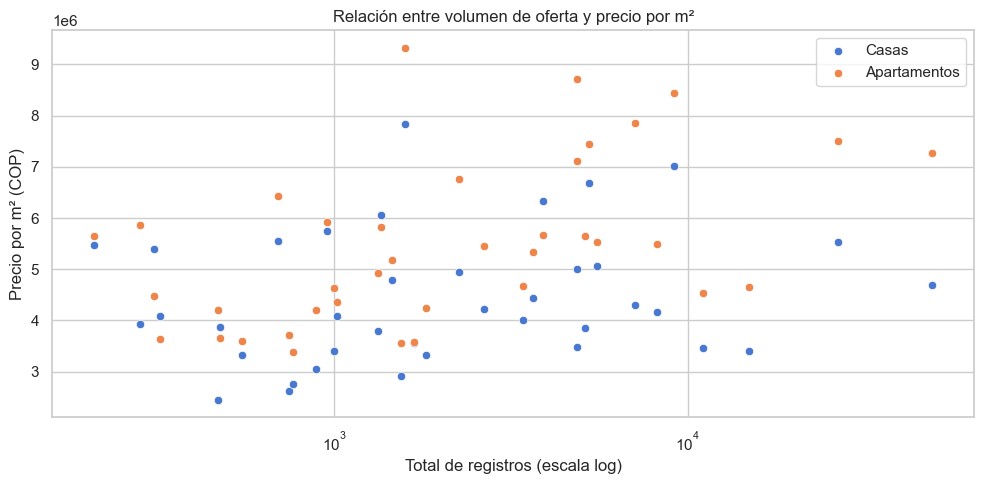

In [19]:
corr_casa = df_enriquecido[["total_registros", "casa_cop_m2"]].corr().iloc[0, 1]
corr_apto = df_enriquecido[["total_registros", "apto_cop_m2"]].corr().iloc[0, 1]

print(f"Correlación volumen vs precio m² casa: {corr_casa:.3f}")
print(f"Correlación volumen vs precio m² apto: {corr_apto:.3f}")

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_enriquecido, x="total_registros", y="casa_cop_m2", label="Casas")
sns.scatterplot(data=df_enriquecido, x="total_registros", y="apto_cop_m2", label="Apartamentos")
plt.xscale("log")
plt.title("Relación entre volumen de oferta y precio por m²")
plt.xlabel("Total de registros (escala log)")
plt.ylabel("Precio por m² (COP)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación:**  
La correlación entre el volumen de oferta y el precio por m² es débil o moderada. Los mercados más grandes (Bogotá, Medellín) no necesariamente presentan los precios más altos de forma lineal.  

Esto sugiere que el precio está más influenciado por factores de localización, turismo, poder adquisitivo y tipología de vivienda que por el simple tamaño de la muestra.

### Pregunta 5  
**Proporción general de costos a escala nacional**

In [20]:
# Promedio simple
promedio_simple = df_enriquecido["diferencia_pct"].mean()

# Promedio ponderado por volumen de oferta
promedio_ponderado = np.average(
    df_enriquecido["diferencia_pct"],
    weights=df_enriquecido["total_registros"]
)

print(f"Diferencia porcentual promedio simple: {promedio_simple:.2f}%")
print(f"Diferencia porcentual promedio ponderado por oferta: {promedio_ponderado:.2f}%")

print("\nDistribución de categorías de brecha:")
display(df_enriquecido["categoria_brecha_precio"].value_counts(normalize=True).mul(100).round(1))

Diferencia porcentual promedio simple: -17.43%
Diferencia porcentual promedio ponderado por oferta: -26.28%

Distribución de categorías de brecha:


categoria_brecha_precio
Descuento Moderado (-15% a -30%)   44.70
Descuento Leve (0% a -15%)         26.30
Descuento Alto (<-30%)             15.80
Casa con Prima (+)                 13.20
Name: proportion, dtype: float64

**Interpretación:**  
A escala nacional, el metro cuadrado de casa presenta, en promedio, un descuento significativo frente al de apartamento (tanto en promedio simple como ponderado).  

La mayoría de las ciudades se ubican en las categorías de “Descuento Moderado” o “Descuento Alto”. Esto indica que, en términos generales, optar por casa implica un menor costo por m², aunque con las particularidades de ubicación y tipología ya analizadas.

## 6. Limitaciones del análisis

- El dataset corresponde a **precios de oferta**, no a transacciones cerradas.
- Algunas ciudades tienen un número muy bajo de registros, lo que reduce la robustez estadística.
- No se controla por estrato socioeconómico, estado de la vivienda, ubicación exacta dentro de la ciudad ni amenidades.
- Los datos son una fotografía de 2026 y pueden no reflejar variaciones estacionales o de corto plazo.
- La clasificación de “casa” y “apartamento” depende de la fuente original y puede incluir tipologías intermedias.

## 7. Exportación de datos finales y generación del reporte .txt

In [21]:
# Crear carpetas si no existen
Path("datos").mkdir(exist_ok=True)
Path("reportes").mkdir(exist_ok=True)

# Exportar DataFrame final enriquecido
df_enriquecido.to_csv("datos/vivienda_colombia_enriquecido.csv", index=False, encoding="utf-8-sig")
df_enriquecido.to_excel("datos/vivienda_colombia_enriquecido.xlsx", index=False)

print("Archivos exportados:")
print(" - datos/vivienda_colombia_enriquecido.csv")
print(" - datos/vivienda_colombia_enriquecido.xlsx")

# Generar reporte .txt automáticamente del DataFrame FINAL
reporte = Reportes()
ruta_txt = reporte.guardar_reporte(
    df_enriquecido,
    "reportes/vivienda_colombia_enriquecido.txt",
    titulo="REPORTE FINAL – DATAFRAME ENRIQUECIDO | CASA VS APARTAMENTO COLOMBIA 2026"
)

print(f"\nReporte .txt generado en: {ruta_txt}")
print("\n" + "="*60)
reporte.imprimir_reporte(df_enriquecido, titulo="REPORTE FINAL – DATAFRAME ENRIQUECIDO")

Archivos exportados:
 - datos/vivienda_colombia_enriquecido.csv
 - datos/vivienda_colombia_enriquecido.xlsx

Reporte .txt generado en: reportes\vivienda_colombia_enriquecido.txt

REPORTE FINAL – DATAFRAME ENRIQUECIDO
Filas: 38
Columnas: 12
Duplicados: 0

Columnas y tipos:
- city: str
- n_si: int64
- n_no: int64
- total_registros: int64
- pct_oferta_casas: float64
- pct_oferta_aptos: float64
- tipo_mercado_dominante: str
- casa_cop_m2: float64
- apto_cop_m2: float64
- brecha_absoluta_cop: float64
- diferencia_pct: float64
- categoria_brecha_precio: str

Valores nulos por columna:
- city: 0
- n_si: 0
- n_no: 0
- total_registros: 0
- pct_oferta_casas: 0
- pct_oferta_aptos: 0
- tipo_mercado_dominante: 0
- casa_cop_m2: 0
- apto_cop_m2: 0
- brecha_absoluta_cop: 0
- diferencia_pct: 0
- categoria_brecha_precio: 0

Estadísticas numéricas:
           n_si      n_no  total_registros  pct_oferta_casas  pct_oferta_aptos  casa_cop_m2  apto_cop_m2  brecha_absoluta_cop  diferencia_pct
count     38.00 

## 8. Conclusiones actualizadas

1. Solo un pequeño grupo de municipios presenta prima en el precio de casas (principalmente zonas campestres o de alto valor percibido).
2. Las mayores brechas de descuento se concentran en ciudades costeras y turísticas.
3. Las áreas metropolitanas muestran comportamientos diferenciados: la Sabana de Bogotá es más heterogénea, mientras que el Valle de Aburrá consolida mercados premium en municipios aledaños.
4. El volumen de oferta no es el principal determinante del precio por m².
5. A escala nacional, el m² de casa es, en promedio, más económico que el de apartamento.

Estos hallazgos actualizan y profundizan las conclusiones del avance anterior (AE2) al incorporar variables de enriquecimiento, categorización y análisis ponderado.